# Import Library


######This section imports all the necessary libraries for data manipulation (Pandas, NumPy), visualization (Matplotlib, Seaborn), image processing (OpenCV, PIL), and model training (scikit-learn, TensorFlow).

In [ ]:
!pip install -q pandas matplotlib seaborn opencv-python scikit-learn
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import shutil
import hashlib
import pathlib as Path
import zipfile
import cv2
import tensorflow as tf
from sklearn.model_selection import train_test_split
from PIL import Image
import random
from glob import glob
from collections import defaultdict
from collections import Counter
from torchvision import transforms
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import Sequence
from tensorflow.keras.models import load_model

Mounted at /content/drive


# Import Dataset

#### Unzip train_images.zip and test_images.zip

In [ ]:
!ls "/content/drive/MyDrive/A2_ML_Ning/Task 3"


EfficientNetB0.h5	 Task_3.ipynb	   test_images	    train_images
meta_train.csv		 Task_3_Mod.ipynb  test_images.zip  train_images.zip
meta_train_filtered.csv  Test		   train_by_age


In [ ]:
## Change this path if your folder name is different
base_path = "/content/drive/MyDrive/A2_ML_Ning/Task 3/"

## Unzip test images
with zipfile.ZipFile(base_path + 'train_images.zip', 'r') as zip_ref:
    zip_ref.extractall(base_path + 'train_images')

print("Train data extraction is done")

Train data extraction is done


In [ ]:
## Change this path if your folder name is different
base_path = "/content/drive/MyDrive/A2_ML_Ning/Task 3/"
## Unzip test images
with zipfile.ZipFile(base_path + 'test_images.zip', 'r') as zip_ref:
    zip_ref.extractall(base_path + 'test_images')

print("Test data extraction is done ✅")

Test data extraction is done ✅


####Read and Analyse Data

In [ ]:
# Read meta_train.csv
meta = pd.read_csv('/content/drive/MyDrive/A2_ML_Ning/Task 3/meta_train.csv')

# Display the first few rows
meta.head()

,image_id,label,variety,age
0,100330.jpg,bacterial_leaf_blight,ADT45,45
1,100365.jpg,bacterial_leaf_blight,ADT45,45
2,100382.jpg,bacterial_leaf_blight,ADT45,45
3,100632.jpg,bacterial_leaf_blight,ADT45,45
4,101918.jpg,bacterial_leaf_blight,ADT45,45


In [ ]:
# Dataset shape
print(f"Number of rows: {meta.shape[0]}")
print(f"Number of columns: {meta.shape[1]}")

# General info
meta.info()

# Basic statistics
meta.describe()


Number of rows: 10407
Number of columns: 4
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10407 entries, 0 to 10406
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  10407 non-null  object
 1   label     10407 non-null  object
 2   variety   10407 non-null  object
 3   age       10407 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 325.3+ KB


,age
count,10407.000000
mean,64.043624
std,8.958830
min,45.000000
25%,60.000000
50%,67.000000
75%,70.000000
max,82.000000


In [ ]:
# Check for missing values
meta.isnull().sum()


,0
image_id,0
label,0
variety,0
age,0


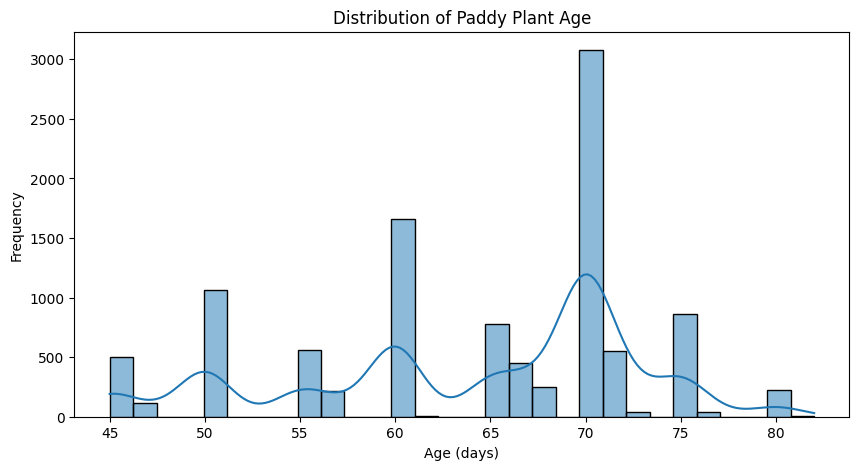

In [ ]:
# Age distribution
plt.figure(figsize=(10,5))
sns.histplot(meta['age'], bins=30, kde=True)
plt.title('Distribution of Paddy Plant Age')
plt.xlabel('Age (days)')
plt.ylabel('Frequency')
plt.show()


# **EDA**

#### **1. Restructuring images by age**

In [ ]:
src_root = "/content/drive/MyDrive/A2_ML_Ning/Task 3/train_images/train_images"
dst_root = "/content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age"
meta_df = pd.read_csv("/content/drive/MyDrive/A2_ML_Ning/Task 3/meta_train.csv")

# Define bins and labels
bins = [44, 50, 55, 60, 65, 70, 75, 85]
labels = ['44–49', '50–54', '55–59', '60–64', '65–69', '70–74', '75–84']

# Add age_bin column
meta_df['age_bin'] = pd.cut(meta_df['age'], bins=bins, labels=labels)

# Create root destination folder
os.makedirs(dst_root, exist_ok=True)

# Loop over rows and copy files
for _, row in meta_df.iterrows():
    image_id = row['image_id']
    label = row['label']
    age_bin = row['age_bin']

    src_path = os.path.join(src_root, label, image_id)
    dst_folder = os.path.join(dst_root, str(age_bin))
    dst_path = os.path.join(dst_folder, image_id)

    os.makedirs(dst_folder, exist_ok=True)

    if os.path.exists(src_path):
        shutil.copy2(src_path, dst_path)
    else:
        print(f"Missing file: {src_path}")


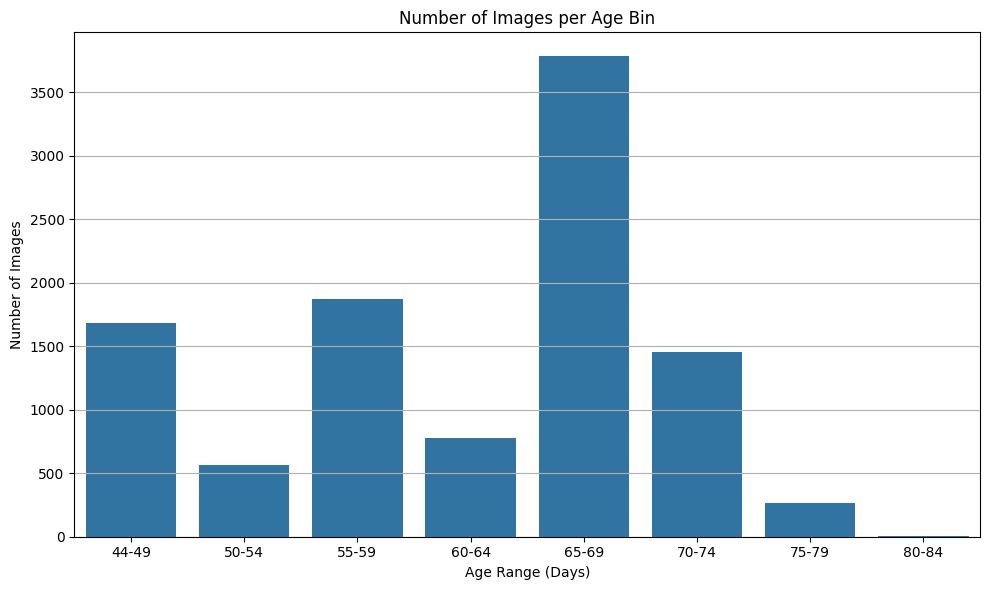

In [ ]:
# Load metadata
meta_df = pd.read_csv("/content/drive/MyDrive/A2_ML_Ning/Task 3/meta_train.csv")

# Define finer bins
bins = [44, 50, 55, 60, 65, 70, 75, 80, 85]
labels = [f"{bins[i]}-{bins[i+1]-1}" for i in range(len(bins)-1)]

# Create age_bin column
meta_df['age_bin'] = pd.cut(meta_df['age'], bins=bins, labels=labels)

# Plot count per age_bin
plt.figure(figsize=(10, 6))
sns.countplot(data=meta_df, x='age_bin', order=labels)
plt.title("Number of Images per Age Bin")
plt.xlabel("Age Range (Days)")
plt.ylabel("Number of Images")
plt.grid(axis='y')
plt.tight_layout()
plt.show()


#### **2. Find duplicated images and deleted**

In [ ]:
def find_and_remove_duplicates_by_age(folder_root, meta_df):
    seen_hashes = {}
    duplicate_count = 0

    # Loop through each sub-folder (each age)
    for age in os.listdir(folder_root):
        age_folder = os.path.join(folder_root, age)

        if not os.path.isdir(age_folder):
            continue

        for filename in os.listdir(age_folder):
            file_path = os.path.join(age_folder, filename)

            # Skip if not a file
            if not os.path.isfile(file_path):
                continue

            try:
                # Open image and compute its hash
                with Image.open(file_path) as img:
                    img_hash = hashlib.md5(img.tobytes()).hexdigest()
            except Exception as e:
                print(f"Skipping corrupted or invalid file: {file_path}")
                continue

            if img_hash in seen_hashes:
                print(f"Duplicate found and removed: {file_path}")
                os.remove(file_path)

                # Remove entry from metadata
                meta_df.drop(meta_df[meta_df['image_id'] == filename].index, inplace=True)
                duplicate_count += 1
            else:
                seen_hashes[img_hash] = file_path

    print(f"\n✅ Total duplicates removed: {duplicate_count}")
    return duplicate_count, meta_df


# === Run the function ===
# Paths
meta_path = "/content/drive/MyDrive/A2_ML_Ning/Task 3/meta_train.csv"
image_root = "/content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age"
output_meta_path = "/content/drive/MyDrive/A2_ML_Ning/Task 3/meta_train_filtered.csv"

# Load metadata
meta_df = pd.read_csv(meta_path)

# Find and remove duplicates
duplicate_count, cleaned_meta_df = find_and_remove_duplicates_by_age(
    folder_root=image_root,
    meta_df=meta_df.copy()
)

# Save updated metadata
cleaned_meta_df.to_csv(output_meta_path, index=False)
print(f"\n✅ Filtered metadata saved to: {output_meta_path}")


Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/104800.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/108353.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/102705.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/105626.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/105840.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/108989.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/104373.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/107078.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/108832.jpg
Duplicate found and removed: /content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/44–49/100602.jpg


In [ ]:
# Load metadata
df = pd.read_csv("/content/drive/MyDrive/A2_ML_Ning/Task 3/meta_train_filtered.csv")

# Create age bins
bins = [44, 49, 54, 59, 64, 69, 74, 79, 84]
labels = ['44-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84']
df['age_bin'] = pd.cut(df['age'], bins=bins, labels=labels, include_lowest=True)

# Caculate sample weights
bin_counts = df['age_bin'].value_counts().sort_index()
weights = len(df) / bin_counts
normalized_weights = weights / weights.sum()
df['sample_weight'] = df['age_bin'].map(normalized_weights)

# Train/val split
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['age_bin'])

# Image size
IMG_SIZE = (224, 224)

# Custom data generator supporting sample weight
class WeightedImageGenerator(Sequence):
    def __init__(self, df, batch_size, img_dir, is_train=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.img_dir = img_dir
        self.is_train = is_train
        self.datagen = tf.keras.preprocessing.image.ImageDataGenerator(
            rescale=1./255,
            horizontal_flip=True if is_train else False
        )

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, idx):
        batch_df = self.df.iloc[idx * self.batch_size:(idx + 1) * self.batch_size]
        images, ages, weights = [], [], []

        for _, row in batch_df.iterrows():
            img_path = glob(os.path.join(self.img_dir, "*", row['image_id']))
            if len(img_path) == 0:
              raise FileNotFoundError(f"Image {row['image_id']} not found in subfolders of {self.img_dir}")
            img_path = img_path[0]
            img = load_img(img_path, target_size=IMG_SIZE)
            img_array = img_to_array(img)
            img_array = self.datagen.random_transform(img_array)
            images.append(img_array)
            ages.append(row['age'])
            weights.append(row['sample_weight'])

        return np.array(images), np.array(ages), np.array(weights)

# Create generators
train_gen = WeightedImageGenerator(train_df, batch_size=32, img_dir="/content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/")
val_gen = WeightedImageGenerator(val_df, batch_size=32, img_dir="/content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age/", is_train=False)

# Build basic model
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train sample_weight
model.fit(train_gen, validation_data=val_gen, epochs=30)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - loss: 112614.3203 - mae: 259.7232

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


259/259 ━━━━━━━━━━━━━━━━━━━━ 111s 405ms/step - loss: 112266.0781 - mae: 258.9590 - val_loss: 7.5950 - val_mae: 8.9972
Epoch 2/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 92s 356ms/step - loss: 6.1551 - mae: 7.8591 - val_loss: 8.3426 - val_mae: 7.5013
Epoch 3/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 91s 351ms/step - loss: 5.2825 - mae: 7.2047 - val_loss: 6.9999 - val_mae: 7.2260
Epoch 4/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 90s 347ms/step - loss: 5.1928 - mae: 7.0609 - val_loss: 6.5548 - val_mae: 7.7238
Epoch 5/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 95s 365ms/step - loss: 5.2992 - mae: 6.8719 - val_loss: 8.6984 - val_mae: 8.6144
Epoch 6/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 93s 361ms/step - loss: 5.8418 - mae: 6.9918 - val_loss: 7.7204 - val_mae: 9.1032
Epoch 7/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 92s 353ms/step - loss: 5.4460 - mae: 6.7004 - val_loss: 7.6682 - val_mae: 8.8397
Epoch 8/30
259/259 ━━━━━━━━━━━━━━━━━━━━ 90s 348ms/step - loss: 5.0606 - mae: 6.5930 - val_loss: 6.1783 - val_mae: 7.0692
Epoch 9/30
259/259 ━━━━━━━━━━━━━━━━

####**3.Display image per label**

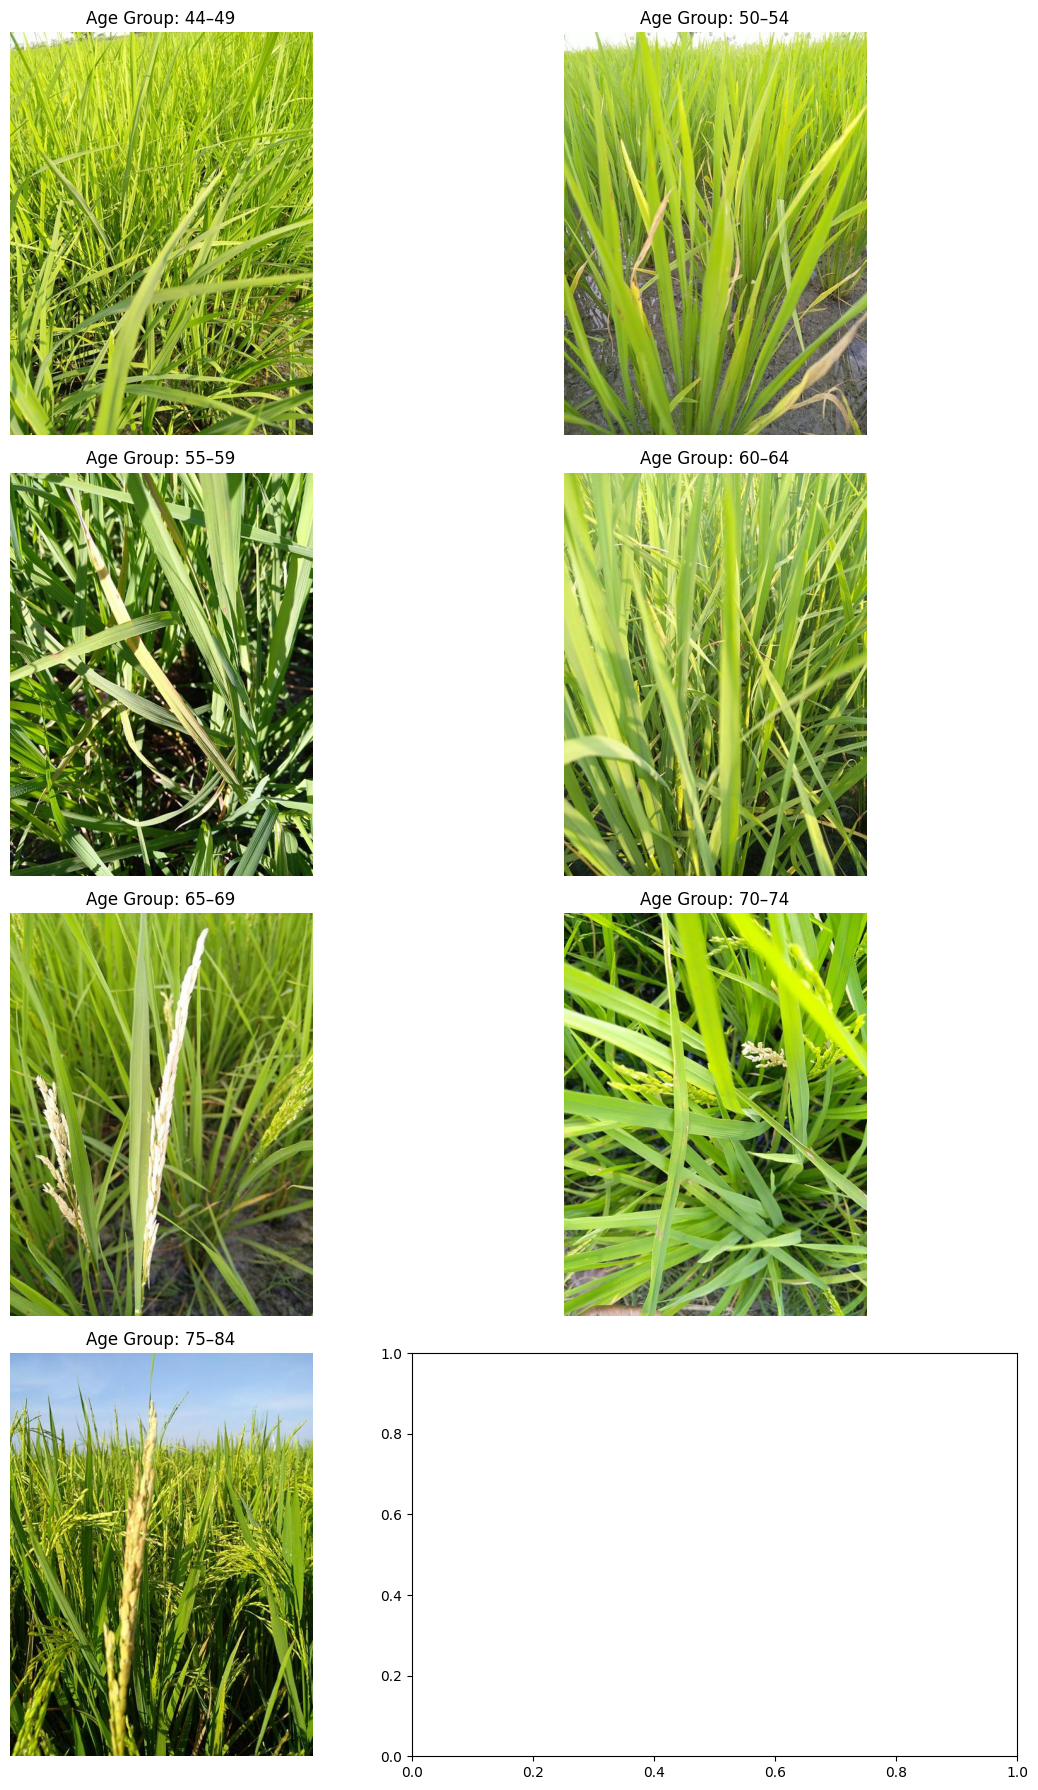

In [ ]:
# Define age bins (must match how you split the folders)
bins = [44, 50, 55, 60, 65, 70, 75, 85]
labels = ['44–49', '50–54', '55–59', '60–64', '65–69', '70–74', '75–84']
meta['age_bin'] = pd.cut(meta['age'], bins=bins, labels=labels)
train_path = '/content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age'

# Get the list of age bins
age_bins = meta['age_bin'].unique().tolist()

# Plot one random image per age bin
fig, axes = plt.subplots(4, 2, figsize=(12, 18))
axes = axes.flatten()

for i, age_group in enumerate(age_bins):
    img_list = glob(os.path.join(train_path, str(age_group), '*.jpg'))

    if len(img_list) == 0:
        print(f"No images found for age group {age_group}. Skipping...")
        continue

    img_path = random.choice(img_list)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(f"Age Group: {age_group}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()


# Model Training

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 7

In [ ]:
# Path to your age-binned image folders
data_dir = "/content/drive/MyDrive/A2_ML_Ning/Task 3/train_by_age"

# Augmentation & preprocessing
datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.4
)
# Train generator
train_generator = datagen.flow_from_directory(
    data_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

# Validation generator
val_generator = datagen.flow_from_directory(
    data_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

Found 6203 images belonging to 7 classes.
Found 4130 images belonging to 7 classes.


In [ ]:
# EfficientNetB0 model
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = True

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(NUM_CLASSES, activation='softmax')  # Classification head
])

In [ ]:
# Compile the model with the Adam optimizer, categorical crossentropy loss
# (suitable for multi-class classification), and accuracy as the evaluation metric.
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
# Train the model using the training data generator for 50 epochs,
# while validating on the validation data after each epoch.
# The training process returns a `history` object that stores loss and accuracy metrics.
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50
)

Epoch 1/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 241s 1s/step - accuracy: 0.4006 - loss: 1.6079 - val_accuracy: 0.0542 - val_loss: 1.9906
Epoch 2/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 209s 969ms/step - accuracy: 0.4407 - loss: 1.5226 - val_accuracy: 0.3639 - val_loss: 2.2616
Epoch 3/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.4484 - loss: 1.4880 - val_accuracy: 0.3596 - val_loss: 2.0133
Epoch 4/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 187s 965ms/step - accuracy: 0.4695 - loss: 1.4118 - val_accuracy: 0.2262 - val_loss: 2.1580
Epoch 5/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 187s 964ms/step - accuracy: 0.4640 - loss: 1.3999 - val_accuracy: 0.3719 - val_loss: 1.8886
Epoch 6/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 185s 955ms/step - accuracy: 0.5242 - loss: 1.2739 - val_accuracy: 0.4714 - val_loss: 1.6780
Epoch 7/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 184s 952ms/step - accuracy: 0.5196 - loss: 1.2456 - val_accuracy: 0.4443 - val_loss: 1.5669
Epoch 8/50
194/194 ━━━━━━━━━━━━━━━━━━━━ 191s 986ms/step - accuracy: 0.5703 - loss:

In [ ]:
def plot_learning_curve(train_loss, val_loss, train_metric, val_metric, metric_name='Accuracy'):
    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.plot(train_loss, 'r--')
    plt.plot(val_loss, 'b--')
    plt.xlabel("epochs")
    plt.ylabel("Loss")
    plt.legend(['train', 'val'], loc='upper left')

    plt.subplot(1,2,2)
    plt.plot(train_metric, 'r--')
    plt.plot(val_metric, 'b--')
    plt.xlabel("epochs")
    plt.ylabel(metric_name)
    plt.legend(['train', 'val'], loc='upper left')

    plt.show()


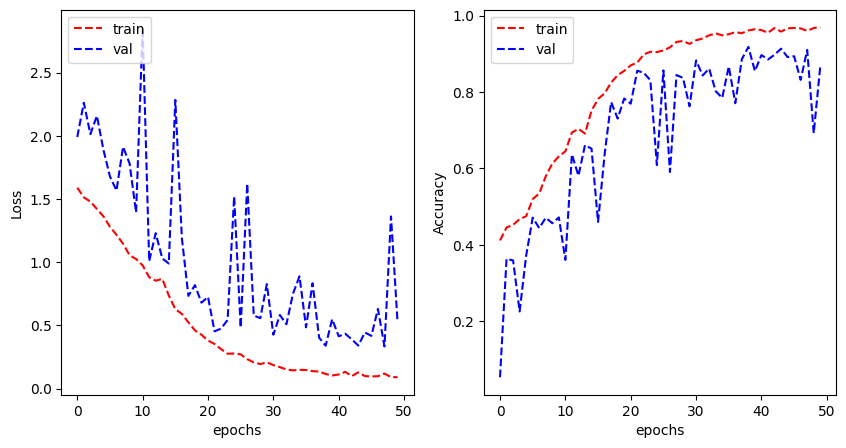

In [ ]:
plot_learning_curve(history.history['loss'], history.history['val_loss'],
                    history.history['accuracy'], history.history['val_accuracy'],
                    metric_name='Accuracy')

In [ ]:
model.save('EfficientNetB0.h5')

In [ ]:
CLASS_LABELS = ['44-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84']
MODEL_PATH = '/content/drive/MyDrive/A2_ML_Ning/Task 3/EfficientNetB0.h5'

In [ ]:
# Save the trained model to a file for later use or inference
model = load_model(MODEL_PATH)

In [ ]:
# Get sorted list of test image filenames ending in .jpg
image_ids = sorted([f for f in os.listdir('/content/drive/MyDrive/A2_ML_Ning/Task 3/test_images/test_images') if f.endswith('.jpg')])
X = []
# Load and preprocess each image
for image_id in image_ids:
    img = load_img(os.path.join('/content/drive/MyDrive/A2_ML_Ning/Task 3/test_images/test_images', image_id), target_size=(IMG_SIZE, IMG_SIZE))
    img_array = img_to_array(img) / 255.0
    X.append(img_array)
# Convert list to NumPy array for prediction
X = np.array(X)
preds = model.predict(X)
predicted_bins = [CLASS_LABELS[np.argmax(p)] for p in preds]

# Predict age bins using the trained model
df = pd.DataFrame({
    'image_id': image_ids,
    'predicted_age': predicted_bins
})

df.to_csv('/content/drive/MyDrive/A2_ML_Ning/Task 3/COSC2753_A2_s1234567_s2345678_s3456789_task3.csv.csv', index=False)
print("✅ Prediction file saved as: /content/drive/MyDrive/A2_ML_Ning/Task 3/task3_predictions.csv")

109/109 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step
✅ Prediction file saved as: /content/drive/MyDrive/A2_ML_Ning/Task 3/task3_predictions.csv
